# Quantum Reservoir Computing (QRC)
Analog neutral-atom reservoir simulation using Bloqade on time-series forecasting.


In [9]:
!pip install -q bloqade-analog==0.16.9 numpy matplotlib scikit-learn pandas

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from bloqade.analog import start

np.random.seed(7)
print("Imports completed.")

Imports completed.


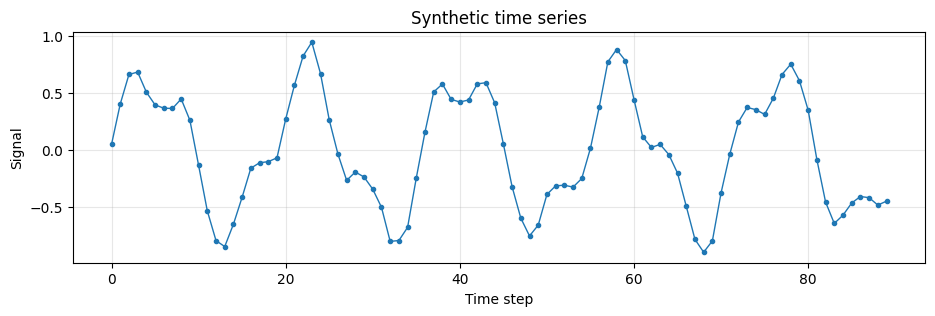

Input window shape: (85, 5)
Training windows: 59
Test windows: 26
One input window: [0.027 0.411 0.693 0.716 0.525]
Target for that window: 0.396


In [11]:
N_POINTS = 90
t = np.arange(N_POINTS)
signal = (
    0.65 * np.sin(2 * np.pi * t / 18)
    + 0.25 * np.sin(2 * np.pi * t / 7)
    + 0.03 * np.random.normal(size=N_POINTS)
)

plt.figure(figsize=(11, 3))
plt.plot(t, signal, marker=".", linewidth=1)
plt.title("Synthetic time series")
plt.xlabel("Time step")
plt.ylabel("Signal")
plt.grid(True, alpha=0.3)
plt.show()

WINDOW = 5          # number of past values in each input sequence
TRAIN_FRACTION = 0.70

# Normalize the input values into a convenient control range.
# This is a simple educational encoding, not a hardware-calibrated mapping.
signal_min, signal_max = signal.min(), signal.max()
signal_scaled = 2 * (signal - signal_min) / (signal_max - signal_min) - 1

X_windows = np.array([
    signal_scaled[i:i + WINDOW] for i in range(N_POINTS - WINDOW)
])
y_targets = np.array([
    signal[i + WINDOW] for i in range(N_POINTS - WINDOW)
])

split = int(len(X_windows) * TRAIN_FRACTION)
X_train, X_test = X_windows[:split], X_windows[split:]
y_train, y_test = y_targets[:split], y_targets[split:]

print("Input window shape:", X_windows.shape)
print("Training windows:", len(X_train))
print("Test windows:", len(X_test))
print("One input window:", np.round(X_windows[0], 3))
print("Target for that window:", round(float(y_targets[0]), 3))

In [12]:
N_ATOMS = 5
SHOTS = 120                 # measurement repetitions per input window
SEGMENT_DURATION = 0.20     # microseconds per input value
RABI_AMPLITUDE = 2.5        # rad / microsecond
DETUNING_SCALE = 2.0        # rad / microsecond

# One-dimensional atom positions, in micrometres.
SPACING = 6.0
positions = [(i * SPACING, 0.0) for i in range(N_ATOMS)]

print("Atom positions:", positions)
print("Total input-encoding duration:", WINDOW * SEGMENT_DURATION, "microseconds")

Atom positions: [(0.0, 0.0), (6.0, 0.0), (12.0, 0.0), (18.0, 0.0), (24.0, 0.0)]
Total input-encoding duration: 1.0 microseconds


In [14]:
def build_reservoir_program(input_window):
    # Map the normalized input sequence to detuning control values.
    detunings = (DETUNING_SCALE * np.asarray(input_window, dtype=float)).tolist()
    durations = [SEGMENT_DURATION] * len(detunings)

    # Define atom positions, then add a uniform Rabi-amplitude waveform,
    # followed by a uniform piecewise-constant detuning waveform.
    program = start.add_position(positions)

    program = (
        program
        .rydberg.rabi.amplitude.uniform
        .constant(duration=sum(durations), value=RABI_AMPLITUDE)
        .detuning.uniform
        .piecewise_constant(durations=durations, values=detunings)
    )
    return program

# Build one example program and inspect its properties instead of printing the whole object string
example_program = build_reservoir_program(X_train[0])
print("Program successfully created!")
print("Atom positions in program:", positions)

Program successfully created!
Atom positions in program: [(0.0, 0.0), (6.0, 0.0), (12.0, 0.0), (18.0, 0.0), (24.0, 0.0)]


In [16]:
def extract_features(input_window, shots=SHOTS):
    program = build_reservoir_program(input_window)

    # Run the analog simulation locally and request a report.
    result = program.bloqade.python().run(shots)
    report = result.report()

    # One array per task; each row is one measurement shot.
    measured_bits = np.asarray(report.bitstrings()[0], dtype=float)

    # Bloqade analog report convention: 0 means Rydberg, 1 means ground.
    rydberg_occupations = 1.0 - measured_bits

    # Mean occupation of each atom across all shots.
    single_atom_means = rydberg_occupations.mean(axis=0)

    # Pairwise occupation correlations across all shots.
    pair_features = []
    for i in range(N_ATOMS):
        for j in range(i + 1, N_ATOMS):
            pair_features.append(
                np.mean(rydberg_occupations[:, i] * rydberg_occupations[:, j])
            )

    features = np.concatenate([single_atom_means, np.asarray(pair_features)])
    return features

# Smoke test: run one window before starting the full experiment.
one_feature_vector = extract_features(X_train[0])
print("Feature-vector shape:", one_feature_vector.shape)
print("Feature values:", np.round(one_feature_vector, 3))

Feature-vector shape: (15,)
Feature values: [0.6   0.283 0.367 0.333 0.517 0.    0.342 0.125 0.35  0.    0.175 0.092
 0.    0.35  0.   ]


In [17]:
def make_feature_matrix(windows, label):
    feature_rows = []
    for index, window in enumerate(windows):
        feature_rows.append(extract_features(window))
        if (index + 1) % 10 == 0 or index + 1 == len(windows):
            print(f"{label}: completed {index + 1}/{len(windows)} windows")
    return np.vstack(feature_rows)

Xq_train = make_feature_matrix(X_train, "Train")
Xq_test = make_feature_matrix(X_test, "Test")

print("Quantum-reservoir training features:", Xq_train.shape)
print("Quantum-reservoir test features:", Xq_test.shape)

Train: completed 10/59 windows
Train: completed 20/59 windows
Train: completed 30/59 windows
Train: completed 40/59 windows
Train: completed 50/59 windows
Train: completed 59/59 windows
Test: completed 10/26 windows
Test: completed 20/26 windows
Test: completed 26/26 windows
Quantum-reservoir training features: (59, 15)
Quantum-reservoir test features: (26, 15)


In [18]:
readout = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)
readout.fit(Xq_train, y_train)

y_pred = readout.predict(Xq_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"QRC test RMSE: {rmse:.4f}")
print(f"QRC test MAE:  {mae:.4f}")

QRC test RMSE: 0.5422
QRC test MAE:  0.4577


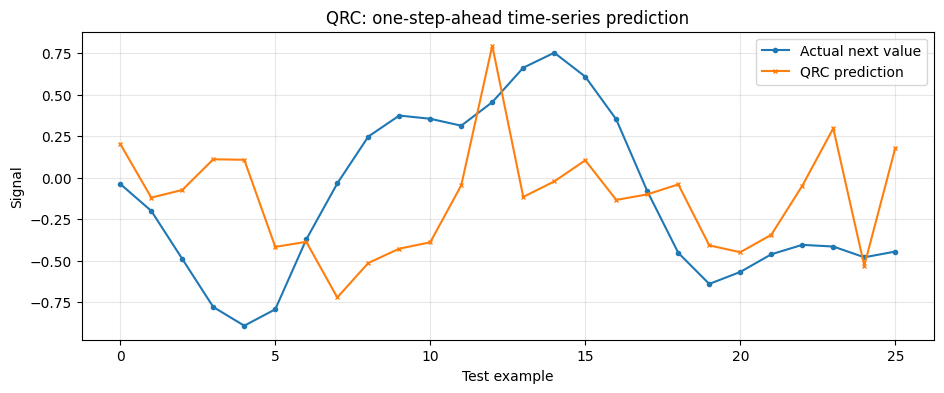

In [19]:
plt.figure(figsize=(11, 4))
plt.plot(y_test, label="Actual next value", marker="o", markersize=3)
plt.plot(y_pred, label="QRC prediction", marker="x", markersize=3)
plt.title("QRC: one-step-ahead time-series prediction")
plt.xlabel("Test example")
plt.ylabel("Signal")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
def inverse_minmax(x):
    return (np.asarray(x) + 1) / 2 * (signal_max - signal_min) + signal_min

persistence_pred = inverse_minmax(X_test[:, -1])

baseline_rmse = np.sqrt(mean_squared_error(y_test, persistence_pred))
baseline_mae = mean_absolute_error(y_test, persistence_pred)

print(f"QRC       RMSE={rmse:.4f} | MAE={mae:.4f}")
print(f"Persistence RMSE={baseline_rmse:.4f} | MAE={baseline_mae:.4f}")

QRC       RMSE=0.5422 | MAE=0.4577
Persistence RMSE=0.2110 | MAE=0.1712
